In [1]:
# Install libraries for loading and exploring datasets
%pip install -q datasets huggingface_hub pandas pyarrow matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Import libraries for dataset loading and analysis
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from huggingface_hub import HfApi

print("Libraries imported successfully!")

c:\Users\ragha\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully!


In [3]:
# Record the dataset revision for reproducibility
api = HfApi()

nf_revision = api.dataset_info("BeIR/nfcorpus").sha
print("NFCorpus revision:", nf_revision)

# Load the NFCorpus document collection
nfcorpus = load_dataset(
    "BeIR/nfcorpus",
    "corpus",
    revision=nf_revision
)

print(nfcorpus)

NFCorpus revision: b5026a0e96e8a7ac4f95f482a596389289d46269
DatasetDict({
    corpus: Dataset({
        features: ['_id', 'title', 'text'],
        num_rows: 3633
    })
})


In [4]:
# Inspect the dataset structure
print("Available splits:", list(nfcorpus.keys()))

nf_split = next(iter(nfcorpus.keys()))
nf_data = nfcorpus[nf_split]

print("Total documents:", len(nf_data))
print("Columns:", nf_data.column_names)

# Look at one example document
print(nf_data[0])

Available splits: ['corpus']
Total documents: 3633
Columns: ['_id', 'title', 'text']
{'_id': 'MED-10', 'title': 'Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland', 'text': 'Recent studies have suggested that statins, an established drug group in the prevention of cardiovascular mortality, could delay or prevent breast cancer recurrence but the effect on disease-specific mortality remains unclear. We evaluated risk of breast cancer death among statin users in a population-based cohort of breast cancer patients. The study cohort included all newly diagnosed breast cancer patients in Finland during 1995–2003 (31,236 cases), identified from the Finnish Cancer Registry. Information on statin use before and after the diagnosis was obtained from a national prescription database. We used the Cox proportional hazards regression method to estimate mortality among statin users with statin use as time-dependent variable. A total of 4,151 participants had used statins. 

In [5]:
# Convert NFCorpus into our shared document format
nf_docs = []

for row in nf_data:
    nf_docs.append({
        "doc_id": str(row["_id"]),
        "title": row["title"] or "",
        "text": row["text"] or "",
        "source": "nfcorpus"
    })

nf_df = pd.DataFrame(nf_docs)

print("DataFrame shape:", nf_df.shape)
print("Unique document IDs:", nf_df["doc_id"].nunique())
print("Missing document texts:", (nf_df["text"].str.strip() == "").sum())

display(nf_df.head())

DataFrame shape: (3633, 4)
Unique document IDs: 3633
Missing document texts: 0


,doc_id,title,text,source
0,MED-10,Statin Use and Breast Cancer Survival: A Natio...,"Recent studies have suggested that statins, an...",nfcorpus
1,MED-14,Statin use after diagnosis of breast cancer an...,BACKGROUND: Preclinical studies have shown tha...,nfcorpus
2,MED-118,Alkylphenols in human milk and their relations...,The aims of this study were to determine the c...,nfcorpus
3,MED-301,Methylmercury: A Potential Environmental Risk ...,Epilepsy or seizure disorder is one of the mos...,nfcorpus
4,MED-306,Sensitivity of Continuous Performance Test (CP...,Hit Reaction Time latencies (HRT) in the Conti...,nfcorpus


In [6]:
# Load the labeled PubMedQA dataset
pubmed_revision = api.dataset_info("qiaojin/PubMedQA").sha

print("PubMedQA revision:", pubmed_revision)

pubmedqa = load_dataset(
    "qiaojin/PubMedQA",
    "pqa_labeled",
    revision=pubmed_revision
)

print(pubmedqa)

PubMedQA revision: 9001f2853fb87cab8d220904e0de81ac6973b318
DatasetDict({
    train: Dataset({
        features: ['pubid', 'question', 'context', 'long_answer', 'final_decision'],
        num_rows: 1000
    })
})


In [7]:
# Check dataset structure before processing
print("Available splits:", list(pubmedqa.keys()))

pubmed_split = next(iter(pubmedqa.keys()))
pubmed_data = pubmedqa[pubmed_split]

print("Total records:", len(pubmed_data))
print("Columns:", pubmed_data.column_names)

# Print one example to understand its structure
print(pubmed_data[0])

Available splits: ['train']
Total records: 1000
Columns: ['pubid', 'question', 'context', 'long_answer', 'final_decision']
{'pubid': 21645374, 'question': 'Do mitochondria play a role in remodelling lace plant leaves during programmed cell death?', 'context': {'contexts': ['Programmed cell death (PCD) is the regulated death of cells within an organism. The lace plant (Aponogeton madagascariensis) produces perforations in its leaves through PCD. The leaves of the plant consist of a latticework of longitudinal and transverse veins enclosing areoles. PCD occurs in the cells at the center of these areoles and progresses outwards, stopping approximately five cells from the vasculature. The role of mitochondria during PCD has been recognized in animals; however, it has been less studied during PCD in plants.', 'The following paper elucidates the role of mitochondrial dynamics during developmentally regulated PCD in vivo in A. madagascariensis. A single areole within a window stage leaf (PCD 

In [8]:
# Examine how PubMedQA stores research abstracts
sample = pubmed_data[0]

print("Document ID:", sample["pubid"])
print("Question:", sample["question"])
print("Context type:", type(sample["context"]))

print("\nContext fields:")
print(sample["context"].keys())

print("\nContext example:")
print(sample["context"])

Document ID: 21645374
Question: Do mitochondria play a role in remodelling lace plant leaves during programmed cell death?
Context type: <class 'dict'>

Context fields:
dict_keys(['contexts', 'labels', 'meshes', 'reasoning_required_pred', 'reasoning_free_pred'])

Context example:
{'contexts': ['Programmed cell death (PCD) is the regulated death of cells within an organism. The lace plant (Aponogeton madagascariensis) produces perforations in its leaves through PCD. The leaves of the plant consist of a latticework of longitudinal and transverse veins enclosing areoles. PCD occurs in the cells at the center of these areoles and progresses outwards, stopping approximately five cells from the vasculature. The role of mitochondria during PCD has been recognized in animals; however, it has been less studied during PCD in plants.', 'The following paper elucidates the role of mitochondrial dynamics during developmentally regulated PCD in vivo in A. madagascariensis. A single areole within a wi

In [9]:
# Convert PubMedQA abstracts into our shared document format
pubmed_docs = []

for row in pubmed_data:
    context = row["context"]
    passages = context.get("contexts") or []

    pubmed_docs.append({
        "doc_id": str(row["pubid"]),
        "title": row["question"],
        "text": "\n\n".join(passages),
        "source": "pubmedqa",
        "sections": passages,
        "section_labels": context.get("labels") or []
    })

pubmed_df = pd.DataFrame(pubmed_docs)

print("DataFrame shape:", pubmed_df.shape)
print("Unique document IDs:", pubmed_df["doc_id"].nunique())
print("Missing abstracts:", (pubmed_df["text"].str.strip() == "").sum())

display(pubmed_df.head())

DataFrame shape: (1000, 6)
Unique document IDs: 1000
Missing abstracts: 0


,doc_id,title,text,source,sections,section_labels
0,21645374,Do mitochondria play a role in remodelling lac...,Programmed cell death (PCD) is the regulated d...,pubmedqa,[Programmed cell death (PCD) is the regulated ...,"[BACKGROUND, RESULTS]"
1,16418930,Landolt C and snellen e acuity: differences in...,Assessment of visual acuity depends on the opt...,pubmedqa,[Assessment of visual acuity depends on the op...,"[BACKGROUND, PATIENTS AND METHODS, RESULTS]"
2,9488747,"Syncope during bathing in infants, a pediatric...",Apparent life-threatening events in infants ar...,pubmedqa,[Apparent life-threatening events in infants a...,"[BACKGROUND, CASE REPORTS]"
3,17208539,Are the long-term results of the transanal pul...,The transanal endorectal pull-through (TERPT) ...,pubmedqa,[The transanal endorectal pull-through (TERPT)...,"[PURPOSE, METHODS, RESULTS]"
4,10808977,Can tailored interventions increase mammograph...,Telephone counseling and tailored print commun...,pubmedqa,[Telephone counseling and tailored print commu...,"[BACKGROUND, DESIGN, PARTICIPANTS, INTERVENTIO..."


In [10]:
# Calculate word counts for both datasets
nf_df["word_count"] = nf_df["text"].apply(
    lambda text: len(text.split())
)

pubmed_df["word_count"] = pubmed_df["text"].apply(
    lambda text: len(text.split())
)

print("NFCorpus document lengths:")
display(nf_df["word_count"].describe())

print("\nPubMedQA abstract lengths:")
display(pubmed_df["word_count"].describe())

NFCorpus document lengths:


count    3633.000000
mean      220.978805
std        82.137592
min        13.000000
25%       173.000000
50%       224.000000
75%       258.000000
max      1460.000000
Name: word_count, dtype: float64


PubMedQA abstract lengths:


count    1000.000000
mean      200.207000
std        51.846429
min        49.000000
25%       166.750000
50%       200.500000
75%       228.000000
max       398.000000
Name: word_count, dtype: float64

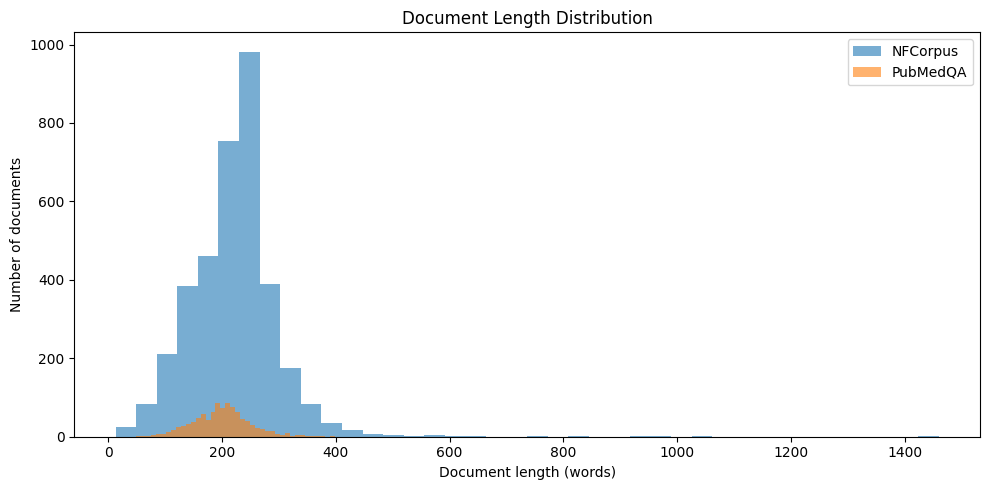

In [11]:
# Visualize document lengths for both datasets
plt.figure(figsize=(10, 5))

plt.hist(
    nf_df["word_count"],
    bins=40,
    alpha=0.6,
    label="NFCorpus"
)

plt.hist(
    pubmed_df["word_count"],
    bins=40,
    alpha=0.6,
    label="PubMedQA"
)

plt.xlabel("Document length (words)")
plt.ylabel("Number of documents")
plt.title("Document Length Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
# Compare document length statistics
summary = pd.DataFrame([
    {
        "Dataset": "NFCorpus",
        "Documents": len(nf_df),
        "Average Words": nf_df["word_count"].mean(),
        "Median Words": nf_df["word_count"].median(),
        "Max Words": nf_df["word_count"].max()
    },
    {
        "Dataset": "PubMedQA",
        "Documents": len(pubmed_df),
        "Average Words": pubmed_df["word_count"].mean(),
        "Median Words": pubmed_df["word_count"].median(),
        "Max Words": pubmed_df["word_count"].max()
    }
])

display(summary.round(2))

,Dataset,Documents,Average Words,Median Words,Max Words
0,NFCorpus,3633,220.98,224.0,1460
1,PubMedQA,1000,200.21,200.5,398


### Part 1 — Dataset Exploration Findings

- Loaded 3,633 NFCorpus documents and 1,000 labeled PubMedQA abstracts.
- Preserved original document IDs, titles, and text.
- Preserved PubMedQA abstract sections for future adaptive chunking.
- NFCorpus documents average 220.98 words, compared with 200.21 for PubMedQA.
- NFCorpus has a wider document-length distribution, including outliers up to 1,460 words.
- These findings motivate comparing fixed-size and structure-aware chunking.
- Actual token counts will be examined before finalizing chunk-size parameters.

In [13]:
# Install the tokenizer library
%pip install -q transformers

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
# Load the tokenizer used by our planned reranker
from transformers import AutoTokenizer

TOKENIZER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"

tokenizer = AutoTokenizer.from_pretrained(
    TOKENIZER_NAME,
    use_fast=True
)

CHUNK_SIZE = 256
CHUNK_OVERLAP = 50

print("Tokenizer:", tokenizer.name_or_path)
print("Vocabulary size:", tokenizer.vocab_size)
print("Chunk size:", CHUNK_SIZE)
print("Overlap:", CHUNK_OVERLAP)

Tokenizer: cross-encoder/ms-marco-MiniLM-L-6-v2
Vocabulary size: 30522
Chunk size: 256
Overlap: 50


In [15]:
# Compare words with tokenizer tokens
sample_text = (
    "Statin therapy may improve survival outcomes "
    "in patients with breast cancer."
)

tokens = tokenizer.tokenize(sample_text)

print("Original text:", sample_text)
print("\nWord count:", len(sample_text.split()))
print("Token count:", len(tokens))
print("\nTokens:", tokens)

Original text: Statin therapy may improve survival outcomes in patients with breast cancer.

Word count: 11
Token count: 13

Tokens: ['stat', '##in', 'therapy', 'may', 'improve', 'survival', 'outcomes', 'in', 'patients', 'with', 'breast', 'cancer', '.']


In [16]:
# Count tokenizer tokens without adding model special tokens
def count_tokens(text):
    return len(
        tokenizer.encode(
            text,
            add_special_tokens=False,
            truncation=False
        )
    )

nf_df["token_count"] = nf_df["text"].apply(count_tokens)
pubmed_df["token_count"] = pubmed_df["text"].apply(count_tokens)

print("NFCorpus token statistics:")
display(nf_df["token_count"].describe())

print("\nPubMedQA token statistics:")
display(pubmed_df["token_count"].describe())

Token indices sequence length is longer than the specified maximum sequence length for this model (632 > 512). Running this sequence through the model will result in indexing errors


NFCorpus token statistics:


count    3633.000000
mean      335.060556
std       134.824424
min        17.000000
25%       252.000000
50%       334.000000
75%       405.000000
max      2335.000000
Name: token_count, dtype: float64


PubMedQA token statistics:


count    1000.000000
mean      307.023000
std        90.173309
min        57.000000
25%       245.000000
50%       302.000000
75%       361.000000
max       648.000000
Name: token_count, dtype: float64

In [17]:
# Check how many documents need more than one chunk
for name, df in [
    ("NFCorpus", nf_df),
    ("PubMedQA", pubmed_df)
]:
    longer_docs = (df["token_count"] > CHUNK_SIZE).sum()

    percentage = 100 * longer_docs / len(df)

    print(f"{name}:")
    print(f"  Total documents: {len(df)}")
    print(f"  Documents over 256 tokens: {longer_docs}")
    print(f"  Percentage: {percentage:.2f}%")
    print()

NFCorpus:
  Total documents: 3633
  Documents over 256 tokens: 2688
  Percentage: 73.99%

PubMedQA:
  Total documents: 1000
  Documents over 256 tokens: 706
  Percentage: 70.60%



In [18]:
# Import reusable fixed-size chunking function
import sys
from pathlib import Path

# Locate the repository root
cwd = Path.cwd()
repo_root = cwd if (cwd / "src").exists() else cwd.parent

sys.path.insert(0, str(repo_root))

from src.chunking.fixed_chunking import fixed_size_chunking

print("Fixed-size chunking module imported!")

Fixed-size chunking module imported!


In [19]:
# Test fixed-size chunking on a real biomedical document
sample_doc = nf_df.iloc[0].to_dict()

sample_chunks = fixed_size_chunking(
    sample_doc,
    tokenizer,
    chunk_size=256,
    overlap=50
)

print("Document ID:", sample_doc["doc_id"])
print("Original tokens:", sample_doc["token_count"])
print("Chunks created:", len(sample_chunks))

for chunk in sample_chunks:
    print("\nChunk ID:", chunk["chunk_id"])
    print("Token range:",
          chunk["metadata"]["start_token"],
          "-",
          chunk["metadata"]["end_token"])
    print("Text preview:", chunk["text"][:200])

Document ID: MED-10
Original tokens: 369
Chunks created: 2

Chunk ID: nfcorpus_MED-10_fixed_256_50_chunk_0
Token range: 0 - 256
Text preview: Recent studies have suggested that statins, an established drug group in the prevention of cardiovascular mortality, could delay or prevent breast cancer recurrence but the effect on disease-specific 

Chunk ID: nfcorpus_MED-10_fixed_256_50_chunk_1
Token range: 206 - 369
Text preview: and treatment selection, both post-diagnostic and pre-diagnostic statin use were associated with lowered risk of breast cancer death (HR 0.46, 95% CI 0.38–0.55 and HR 0.54, 95% CI 0.44–0.67, respectiv


In [20]:
# Check that chunks follow the configured token windows
encoded = tokenizer(
    sample_doc["text"],
    add_special_tokens=False,
    return_offsets_mapping=True,
    truncation=False
)

offsets = encoded["offset_mapping"]

assert len(sample_chunks) > 0

for chunk in sample_chunks:
    meta = chunk["metadata"]

    assert meta["end_token"] - meta["start_token"] <= CHUNK_SIZE

    assert chunk["text"] == sample_doc["text"][
        meta["start_char"]:meta["end_char"]
    ]

    assert meta["start_char"] == offsets[meta["start_token"]][0]
    assert meta["end_char"] == offsets[meta["end_token"] - 1][1]

for previous, current in zip(sample_chunks, sample_chunks[1:]):
    assert (
        current["metadata"]["start_token"]
        == previous["metadata"]["start_token"]
        + CHUNK_SIZE - CHUNK_OVERLAP
    )

print("All chunk boundary checks passed!")

All chunk boundary checks passed!


In [21]:
# Apply fixed-size chunking to the entire NFCorpus
nf_chunks = []

for doc in nf_df.to_dict("records"):
    chunks = fixed_size_chunking(
        doc,
        tokenizer,
        chunk_size=CHUNK_SIZE,
        overlap=CHUNK_OVERLAP
    )
    nf_chunks.extend(chunks)

print("Original documents:", len(nf_df))
print("Total chunks:", len(nf_chunks))
print("Average chunks per document:", round(len(nf_chunks) / len(nf_df), 2))

nf_chunks_df = pd.DataFrame(nf_chunks)
display(nf_chunks_df.head())

Original documents: 3633
Total chunks: 6827
Average chunks per document: 1.88


,doc_id,chunk_id,text,metadata
0,MED-10,nfcorpus_MED-10_fixed_256_50_chunk_0,"Recent studies have suggested that statins, an...","{'source': 'nfcorpus', 'chunking_method': 'fix..."
1,MED-10,nfcorpus_MED-10_fixed_256_50_chunk_1,"and treatment selection, both post-diagnostic ...","{'source': 'nfcorpus', 'chunking_method': 'fix..."
2,MED-14,nfcorpus_MED-14_fixed_256_50_chunk_0,BACKGROUND: Preclinical studies have shown tha...,"{'source': 'nfcorpus', 'chunking_method': 'fix..."
3,MED-14,nfcorpus_MED-14_fixed_256_50_chunk_1,ensity score methods and a case-control approa...,"{'source': 'nfcorpus', 'chunking_method': 'fix..."
4,MED-118,nfcorpus_MED-118_fixed_256_50_chunk_0,The aims of this study were to determine the c...,"{'source': 'nfcorpus', 'chunking_method': 'fix..."


In [22]:
# Apply fixed-size chunking to PubMedQA abstracts
pubmed_chunks = []

for doc in pubmed_df.to_dict("records"):
    chunks = fixed_size_chunking(
        doc,
        tokenizer,
        chunk_size=CHUNK_SIZE,
        overlap=CHUNK_OVERLAP
    )
    pubmed_chunks.extend(chunks)

print("Original documents:", len(pubmed_df))
print("Total chunks:", len(pubmed_chunks))
print("Average chunks per document:", round(len(pubmed_chunks) / len(pubmed_df), 2))

pubmed_chunks_df = pd.DataFrame(pubmed_chunks)
display(pubmed_chunks_df.head())

Original documents: 1000
Total chunks: 1756
Average chunks per document: 1.76


,doc_id,chunk_id,text,metadata
0,21645374,pubmedqa_21645374_fixed_256_50_chunk_0,Programmed cell death (PCD) is the regulated d...,"{'source': 'pubmedqa', 'chunking_method': 'fix..."
1,21645374,pubmedqa_21645374_fixed_256_50_chunk_1,CD). Window stage leaves were stained with the...,"{'source': 'pubmedqa', 'chunking_method': 'fix..."
2,16418930,pubmedqa_16418930_fixed_256_50_chunk_0,Assessment of visual acuity depends on the opt...,"{'source': 'pubmedqa', 'chunking_method': 'fix..."
3,16418930,pubmedqa_16418930_fixed_256_50_chunk_1,"subjects, were evaluated.\n\nDifferences betwe...","{'source': 'pubmedqa', 'chunking_method': 'fix..."
4,9488747,pubmedqa_9488747_fixed_256_50_chunk_0,Apparent life-threatening events in infants ar...,"{'source': 'pubmedqa', 'chunking_method': 'fix..."


In [23]:
# Compare chunking statistics for both datasets
chunk_summary = []

for name, docs_df, chunks_df in [
    ("NFCorpus", nf_df, nf_chunks_df),
    ("PubMedQA", pubmed_df, pubmed_chunks_df)
]:
    token_lengths = chunks_df["metadata"].apply(
        lambda m: m["end_token"] - m["start_token"]
    )

    chunks_per_doc = chunks_df.groupby("doc_id").size()

    chunk_summary.append({
        "Dataset": name,
        "Documents": len(docs_df),
        "Total Chunks": len(chunks_df),
        "Avg Chunks/Doc": chunks_per_doc.mean(),
        "Avg Tokens/Chunk": token_lengths.mean(),
        "Min Tokens/Chunk": token_lengths.min(),
        "Max Tokens/Chunk": token_lengths.max()
    })

chunk_summary_df = pd.DataFrame(chunk_summary)

display(chunk_summary_df.round(2))

,Dataset,Documents,Total Chunks,Avg Chunks/Doc,Avg Tokens/Chunk,Min Tokens/Chunk,Max Tokens/Chunk
0,NFCorpus,3633,6827,1.88,201.70,17,256
1,PubMedQA,1000,1756,1.76,196.37,51,256


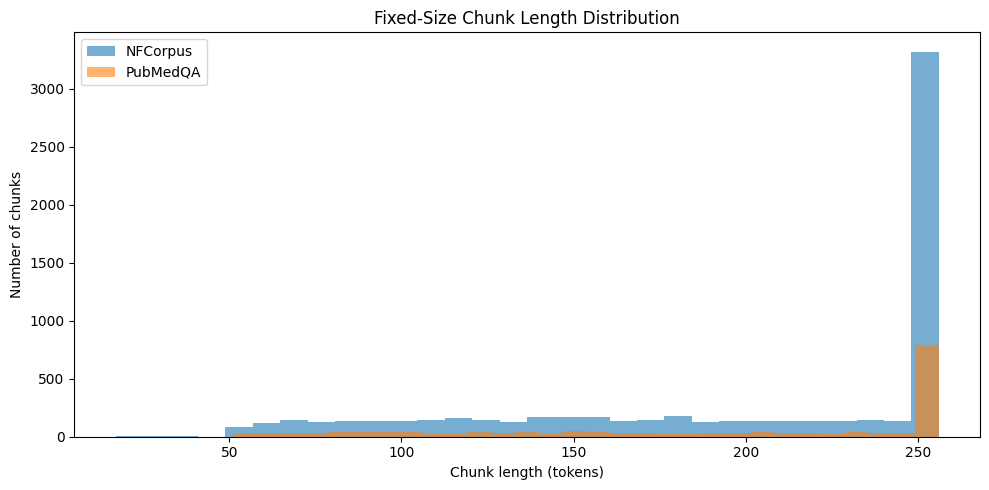

In [24]:
# Compare token lengths of generated chunks
nf_lengths = nf_chunks_df["metadata"].apply(
    lambda m: m["end_token"] - m["start_token"]
)

pubmed_lengths = pubmed_chunks_df["metadata"].apply(
    lambda m: m["end_token"] - m["start_token"]
)

plt.figure(figsize=(10, 5))

plt.hist(nf_lengths, bins=30, alpha=0.6, label="NFCorpus")
plt.hist(pubmed_lengths, bins=30, alpha=0.6, label="PubMedQA")

plt.xlabel("Chunk length (tokens)")
plt.ylabel("Number of chunks")
plt.title("Fixed-Size Chunk Length Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
# Verify unique IDs and valid token boundaries
for name, docs_df, chunks_df in [
    ("NFCorpus", nf_df, nf_chunks_df),
    ("PubMedQA", pubmed_df, pubmed_chunks_df)
]:
    assert chunks_df["chunk_id"].is_unique

    original_ids = set(docs_df["doc_id"])
    chunk_doc_ids = set(chunks_df["doc_id"])

    assert chunk_doc_ids == original_ids

    lengths = chunks_df["metadata"].apply(
        lambda m: m["end_token"] - m["start_token"]
    )

    assert lengths.between(1, CHUNK_SIZE).all()

    print(f"{name}: All chunk integrity checks passed!")

NFCorpus: All chunk integrity checks passed!
PubMedQA: All chunk integrity checks passed!


In [26]:
# Verify chunk boundaries for every document
def validate_chunking(docs_df, chunks_df):
    chunks_by_doc = {
        doc_id: group.to_dict("records")
        for doc_id, group in chunks_df.groupby("doc_id", sort=False)
    }

    for doc in docs_df.to_dict("records"):
        chunks = chunks_by_doc[doc["doc_id"]]
        total_tokens = doc["token_count"]

        # First chunk must start at the beginning
        assert chunks[0]["metadata"]["start_token"] == 0

        # Last chunk must reach the end
        assert chunks[-1]["metadata"]["end_token"] == total_tokens

        for i, chunk in enumerate(chunks):
            meta = chunk["metadata"]

            # Verify valid token boundaries
            assert 0 <= meta["start_token"] < meta["end_token"]
            assert meta["end_token"] <= total_tokens
            assert meta["end_token"] - meta["start_token"] <= CHUNK_SIZE

            # Verify text matches original character positions
            assert chunk["text"] == doc["text"][
                meta["start_char"]:meta["end_char"]
            ]

            if i > 0:
                prev = chunks[i - 1]["metadata"]

                # Verify exact overlap between consecutive chunks
                assert (
                    prev["end_token"] - meta["start_token"]
                    == CHUNK_OVERLAP
                )

    print("All documents passed chunk coverage and overlap checks!")


validate_chunking(nf_df, nf_chunks_df)
validate_chunking(pubmed_df, pubmed_chunks_df)

All documents passed chunk coverage and overlap checks!
All documents passed chunk coverage and overlap checks!


In [27]:
# Verify the reusable function produces the same result
test_doc = nf_df.iloc[0].to_dict()

module_chunks = fixed_size_chunking(
    test_doc,
    tokenizer,
    chunk_size=256,
    overlap=50
)

assert len(module_chunks) == 2
assert module_chunks[0]["metadata"]["start_token"] == 0
assert module_chunks[-1]["metadata"]["end_token"] == test_doc["token_count"]

print("Reusable chunking module works correctly!")

Reusable chunking module works correctly!


## Part 2 — Fixed-Size Chunking

### Objective
Implement fixed-size token-based chunking for NFCorpus and PubMedQA to prepare biomedical documents for retrieval in our RAG pipeline.

### 1. What is Fixed-Size Chunking?
Fixed-size chunking divides documents into smaller text segments based on a predefined token limit, regardless of sentence or paragraph boundaries.

**Configuration:**
- **Tokenizer:** `cross-encoder/ms-marco-MiniLM-L-6-v2`
- **Chunk size:** 256 tokens
- **Overlap:** 50 tokens
- **Step size:** 206 tokens (256 − 50)

Overlap preserves context between neighboring chunks and reduces information loss at boundaries.

### 2. Implementation
Implemented `fixed_size_chunking()` in `src/chunking/fixed_chunking.py`.

The function:
1. Tokenizes each document and obtains character offsets.
2. Creates sliding windows of up to 256 tokens.
3. Extracts the original text using character offsets.
4. Preserves the parent document ID and generates unique chunk IDs.
5. Stores metadata including source, chunk size, overlap, and token boundaries.

### 3. Experimental Results

| Metric | NFCorpus | PubMedQA |
|---|---:|---:|
| Original documents | 3,633 | 1,000 |
| Total chunks | 6,827 | 1,756 |
| Average chunks/document | 1.88 | 1.76 |
| Average tokens/chunk | 201.70 | 196.37 |
| Minimum tokens/chunk | 17 | 51 |
| Maximum tokens/chunk | 256 | 256 |

**Total: 8,583 chunks generated from 4,633 documents.**

### 4. Validation
- Verified unique chunk IDs and preservation of original document IDs.
- Checked chunk boundaries and maximum token lengths.
- Verified token overlap and original text preservation.
- Tested chunking on individual documents and the complete datasets.

### 5. Observations
- Most full-sized chunks contain 256 tokens; final chunks are generally shorter.
- Fixed-size chunking can split sentences and biomedical concepts across boundaries.
- Overlap introduces repeated text and increases the number of indexed passages.
- Chunking increases retrieval granularity but does not guarantee better retrieval accuracy.

### 6. Next Step
Implement **adaptive chunking** using sentence and section boundaries, then compare chunk counts, context preservation, retrieval accuracy, and latency against this fixed-size baseline.

In [28]:
# Install spaCy for sentence segmentation
%pip install -q spacy

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
# Create a lightweight English sentence segmenter
import spacy

nlp = spacy.blank("en")
nlp.add_pipe("sentencizer")

print("Sentence segmenter ready!")
print("Pipeline:", nlp.pipe_names)

Sentence segmenter ready!
Pipeline: ['sentencizer']


In [30]:
# Examine sentence boundaries in a biomedical document
sample_text = nf_df.iloc[0]["text"]

sentences = list(nlp(sample_text).sents)

print("Document ID:", nf_df.iloc[0]["doc_id"])
print("Total sentences:", len(sentences))

for i, sentence in enumerate(sentences[:5]):
    print(f"\nSentence {i + 1}:")
    print(sentence.text)

Document ID: MED-10
Total sentences: 10

Sentence 1:
Recent studies have suggested that statins, an established drug group in the prevention of cardiovascular mortality, could delay or prevent breast cancer recurrence but the effect on disease-specific mortality remains unclear.

Sentence 2:
We evaluated risk of breast cancer death among statin users in a population-based cohort of breast cancer patients.

Sentence 3:
The study cohort included all newly diagnosed breast cancer patients in Finland during 1995–2003 (31,236 cases), identified from the Finnish Cancer Registry.

Sentence 4:
Information on statin use before and after the diagnosis was obtained from a national prescription database.

Sentence 5:
We used the Cox proportional hazards regression method to estimate mortality among statin users with statin use as time-dependent variable.


In [31]:
# Inspect the original sections of a PubMedQA abstract
sample_pubmed = pubmed_df.iloc[0]

sections = sample_pubmed["sections"]
labels = sample_pubmed["section_labels"]

print("Document ID:", sample_pubmed["doc_id"])
print("Total sections:", len(sections))

for i, section in enumerate(sections):
    label = labels[i] if i < len(labels) else "UNLABELED"

    token_count = len(
        tokenizer.encode(
            section,
            add_special_tokens=False,
            truncation=False
        )
    )

    print(f"\nSection {i + 1}: {label}")
    print("Tokens:", token_count)
    print("Preview:", section[:200])

Document ID: 21645374
Total sections: 2

Section 1: BACKGROUND
Tokens: 118
Preview: Programmed cell death (PCD) is the regulated death of cells within an organism. The lace plant (Aponogeton madagascariensis) produces perforations in its leaves through PCD. The leaves of the plant co

Section 2: RESULTS
Tokens: 251
Preview: The following paper elucidates the role of mitochondrial dynamics during developmentally regulated PCD in vivo in A. madagascariensis. A single areole within a window stage leaf (PCD is occurring) was


In [53]:
# Import reusable adaptive chunking function
import sys
from pathlib import Path

cwd = Path.cwd()
repo_root = cwd if (cwd / "src").exists() else cwd.parent

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.chunking.adaptive_chunking import adaptive_chunking

print("Adaptive chunking module imported!")

Adaptive chunking module imported!


In [54]:
# Test the imported adaptive chunking module
import inspect

print("Module location:", inspect.getfile(adaptive_chunking))

test_nf = nf_df.iloc[0].to_dict()
test_pubmed = pubmed_df.iloc[0].to_dict()

for doc in [test_nf, test_pubmed]:
    chunks = adaptive_chunking(
        doc,
        tokenizer,
        nlp,
        max_tokens=256
    )

    assert chunks
    assert validate_adaptive_text(doc, chunks)

    for chunk in chunks:
        token_count = len(tokenizer.encode(
            chunk["text"],
            add_special_tokens=False,
            truncation=False
        ))

        assert 0 < token_count <= 256

    print(
        f"{doc['source']} | {doc['doc_id']} | "
        f"{len(chunks)} chunks | Passed"
    )

print("Adaptive chunking module tests passed!")

Module location: d:\NLP\Adaptive RAG\Adaptive-MedRAG\src\chunking\adaptive_chunking.py
nfcorpus | MED-10 | 2 chunks | Passed
pubmedqa | 21645374 | 2 chunks | Passed
Adaptive chunking module tests passed!


In [40]:
# Test sentence-aware chunking on one NFCorpus document
sample_nf = nf_df.iloc[0].to_dict()

adaptive_nf = adaptive_chunking(
    sample_nf,
    tokenizer,
    nlp,
    max_tokens=256
)

print("Document:", sample_nf["doc_id"])
print("Original tokens:", sample_nf["token_count"])
print("Chunks generated:", len(adaptive_nf))

for chunk in adaptive_nf:
    print("\nChunk ID:", chunk["chunk_id"])
    print("Tokens:", len(tokenizer.encode(
        chunk["text"],
        add_special_tokens=False
    )))
    print("Preview:", chunk["text"][:180])

Document: MED-10
Original tokens: 369
Chunks generated: 2

Chunk ID: nfcorpus_MED-10_adaptive_256_chunk_0
Tokens: 198
Preview: Recent studies have suggested that statins, an established drug group in the prevention of cardiovascular mortality, could delay or prevent breast cancer recurrence but the effect 

Chunk ID: nfcorpus_MED-10_adaptive_256_chunk_1
Tokens: 171
Preview: After adjustment for age, tumor characteristics, and treatment selection, both post-diagnostic and pre-diagnostic statin use were associated with lowered risk of breast cancer deat


In [41]:
# Test section-aware chunking on one PubMedQA abstract
sample_pubmed = pubmed_df.iloc[0].to_dict()

adaptive_pubmed = adaptive_chunking(
    sample_pubmed,
    tokenizer,
    nlp,
    max_tokens=256
)

print("Document:", sample_pubmed["doc_id"])
print("Original tokens:", sample_pubmed["token_count"])
print("Original sections:", len(sample_pubmed["sections"]))
print("Chunks generated:", len(adaptive_pubmed))

for chunk in adaptive_pubmed:
    print("\nChunk ID:", chunk["chunk_id"])
    print("Section index:", chunk["metadata"]["section_index"])
    print("Tokens:", len(tokenizer.encode(
        chunk["text"],
        add_special_tokens=False
    )))
    print("Preview:", chunk["text"][:180])

Document: 21645374
Original tokens: 369
Original sections: 2
Chunks generated: 2

Chunk ID: pubmedqa_21645374_adaptive_256_chunk_0
Section index: 0
Tokens: 118
Preview: Programmed cell death (PCD) is the regulated death of cells within an organism. The lace plant (Aponogeton madagascariensis) produces perforations in its leaves through PCD. The le

Chunk ID: pubmedqa_21645374_adaptive_256_chunk_1
Section index: 1
Tokens: 251
Preview: The following paper elucidates the role of mitochondrial dynamics during developmentally regulated PCD in vivo in A. madagascariensis. A single areole within a window stage leaf (P


In [42]:
# Test the adaptive algorithm on different document lengths
test_docs = [
    nf_df.loc[nf_df["token_count"].idxmin()].to_dict(),
    nf_df.iloc[0].to_dict(),
    nf_df.loc[nf_df["token_count"].idxmax()].to_dict(),
    pubmed_df.iloc[0].to_dict(),
    pubmed_df.loc[pubmed_df["token_count"].idxmax()].to_dict()
]

for doc in test_docs:
    chunks = adaptive_chunking(
        doc, tokenizer, nlp, max_tokens=256
    )

    lengths = [
        len(tokenizer.encode(
            c["text"],
            add_special_tokens=False,
            truncation=False
        ))
        for c in chunks
    ]

    assert chunks, f"No chunks for {doc['doc_id']}"
    assert all(0 < n <= 256 for n in lengths)
    assert len(set(c["chunk_id"] for c in chunks)) == len(chunks)

    print(
        f"{doc['source']} | {doc['doc_id']} | "
        f"{doc['token_count']} tokens | "
        f"{len(chunks)} chunks | "
        f"Max: {max(lengths)}"
    )

print("\nSample integrity tests passed!")

nfcorpus | MED-5063 | 17 tokens | 1 chunks | Max: 17
nfcorpus | MED-10 | 369 tokens | 2 chunks | Max: 198
nfcorpus | MED-957 | 2335 tokens | 11 chunks | Max: 250
pubmedqa | 21645374 | 369 tokens | 2 chunks | Max: 251
pubmedqa | 12632437 | 648 tokens | 6 chunks | Max: 252

Sample integrity tests passed!


In [47]:
# Recheck the document that previously failed
fixed_chunks = adaptive_chunking(
    problem_doc, tokenizer, nlp, max_tokens=256
)

print("Chunks generated:", len(fixed_chunks))

for chunk in fixed_chunks:
    m = chunk["metadata"]
    token_length = len(tokenizer(
        chunk["text"],
        add_special_tokens=False
    )["input_ids"])

    print(
        chunk["chunk_id"],
        "| tokens:", token_length,
        "| chars:", m["start_char"], "-", m["end_char"]
    )

    assert 0 < token_length <= 256
    assert chunk["text"] == problem_doc["text"][
        m["start_char"]:m["end_char"]
    ]

Chunks generated: 6
pubmedqa_12632437_adaptive_256_chunk_0 | tokens: 20 | chars: 0 - 104
pubmedqa_12632437_adaptive_256_chunk_1 | tokens: 206 | chars: 106 - 997
pubmedqa_12632437_adaptive_256_chunk_2 | tokens: 136 | chars: 999 - 1294
pubmedqa_12632437_adaptive_256_chunk_3 | tokens: 252 | chars: 1295 - 1883
pubmedqa_12632437_adaptive_256_chunk_4 | tokens: 27 | chars: 1883 - 1917
pubmedqa_12632437_adaptive_256_chunk_5 | tokens: 7 | chars: 1918 - 1963


In [48]:
# Check that all non-whitespace text is preserved in order
def validate_adaptive_text(doc, chunks):
    text = doc["text"]
    cursor = 0

    for chunk in chunks:
        meta = chunk["metadata"]
        start = meta["start_char"]
        end = meta["end_char"]

        assert start >= cursor, "Overlapping or reordered chunks"
        assert not text[cursor:start].strip(), "Text missing between chunks"
        assert chunk["text"] == text[start:end], "Chunk text mismatch"

        cursor = end

    assert not text[cursor:].strip(), "Text missing after last chunk"

    return True


assert validate_adaptive_text(problem_doc, fixed_chunks)

print("Text coverage validation passed!")

Text coverage validation passed!


In [55]:
# Validate adaptive chunking on all documents
from tqdm.auto import tqdm

adaptive_nf_chunks = []
adaptive_pubmed_chunks = []

for doc in tqdm(nf_df.to_dict("records"), desc="NFCorpus"):
    chunks = adaptive_chunking(doc, tokenizer, nlp, max_tokens=256)
    assert validate_adaptive_text(doc, chunks)
    adaptive_nf_chunks.extend(chunks)

for doc in tqdm(pubmed_df.to_dict("records"), desc="PubMedQA"):
    chunks = adaptive_chunking(doc, tokenizer, nlp, max_tokens=256)
    assert validate_adaptive_text(doc, chunks)
    adaptive_pubmed_chunks.extend(chunks)

print("NFCorpus adaptive chunks:", len(adaptive_nf_chunks))
print("PubMedQA adaptive chunks:", len(adaptive_pubmed_chunks))
print("All text coverage checks passed!")

NFCorpus:   0%|          | 0/3633 [00:00<?, ?it/s]

PubMedQA: 100%|██████████| 1000/1000 [00:02<00:00, 423.51it/s]

NFCorpus adaptive chunks: 6770
PubMedQA adaptive chunks: 3446
All text coverage checks passed!


In [56]:
# Verify chunk sizes and unique IDs
for name, chunks in [
    ("NFCorpus", adaptive_nf_chunks),
    ("PubMedQA", adaptive_pubmed_chunks)
]:
    lengths = [
        len(tokenizer.encode(
            chunk["text"],
            add_special_tokens=False,
            truncation=False
        ))
        for chunk in chunks
    ]

    assert all(0 < length <= 256 for length in lengths)
    assert len({chunk["chunk_id"] for chunk in chunks}) == len(chunks)

    print(f"{name}:")
    print("  Total chunks:", len(chunks))
    print("  Average tokens:", round(sum(lengths) / len(lengths), 2))
    print("  Maximum tokens:", max(lengths))
    print("  Validation passed!\n")

NFCorpus:
  Total chunks: 6770
  Average tokens: 179.8
  Maximum tokens: 256
  Validation passed!

PubMedQA:
  Total chunks: 3446
  Average tokens: 89.1
  Maximum tokens: 256
  Validation passed!



In [51]:
# Compare fixed-size and adaptive chunking results
comparison = []

for name, docs_df, fixed_chunks, adaptive_chunks in [
    ("NFCorpus", nf_df, nf_chunks, adaptive_nf_chunks),
    ("PubMedQA", pubmed_df, pubmed_chunks, adaptive_pubmed_chunks)
]:
    for method, chunks in [
        ("Fixed", fixed_chunks),
        ("Adaptive", adaptive_chunks)
    ]:
        lengths = [
            len(tokenizer.encode(
                chunk["text"],
                add_special_tokens=False,
                truncation=False
            ))
            for chunk in chunks
        ]

        comparison.append({
            "Dataset": name,
            "Method": method,
            "Documents": len(docs_df),
            "Total Chunks": len(chunks),
            "Avg Chunks/Doc": len(chunks) / len(docs_df),
            "Avg Tokens/Chunk": sum(lengths) / len(lengths),
            "Min Tokens": min(lengths),
            "Max Tokens": max(lengths)
        })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(2))

,Dataset,Method,Documents,Total Chunks,Avg Chunks/Doc,Avg Tokens/Chunk,Min Tokens,Max Tokens
0,NFCorpus,Fixed,3633,6827,1.88,201.71,17,257
1,NFCorpus,Adaptive,3633,6770,1.86,179.80,2,256
2,PubMedQA,Fixed,1000,1756,1.76,196.38,51,257
3,PubMedQA,Adaptive,1000,3446,3.45,89.10,2,256


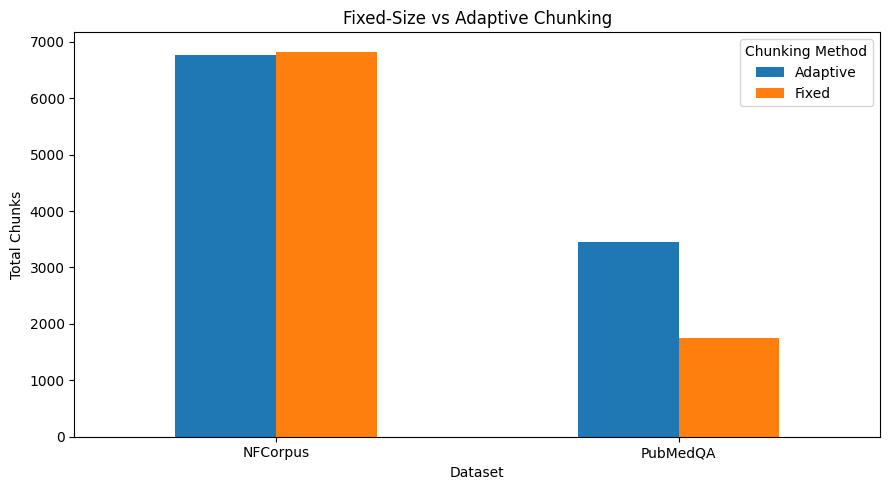

In [52]:
# Compare total chunks generated by each method
import matplotlib.pyplot as plt

pivot = comparison_df.pivot(
    index="Dataset",
    columns="Method",
    values="Total Chunks"
)

ax = pivot.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Fixed-Size vs Adaptive Chunking")
plt.xlabel("Dataset")
plt.ylabel("Total Chunks")
plt.legend(title="Chunking Method")
plt.tight_layout()
plt.show()